# Validation
# Setup
Running this notebook demonstrates the capabilities of our models.

**In the validation_config.yaml change the "model" variable at the top for the model you wish to evaluate**

## Imports

In [3]:
#For some reason the model import breaks if you don't do it first
import sys
import os
#Set parent path to the root of the repo, to be able to import models
parent_dir = os.path.abspath(os.path.join(os.getcwd(), '..'))
sys.path.insert(0, parent_dir)
from models.adapterDETR import AdapterDetr

In [4]:
import torch
import torchmetrics 
from torchvision.ops import box_convert
import importlib.util

from validation.validation_functions import *
from models.adapterDETR import AdapterDetr
from data.dataloader import get_dataloader

# Add the 'detr' package's root to sys.path for its inner imports to work
detr_root = os.path.join(parent_dir, 'detr') # ~/ODCE/detr/
sys.path.insert(0, detr_root)

from hydra.utils import instantiate
from detr.models.matcher import HungarianMatcher
from detr.models.detr    import SetCriterion

## Config

In [5]:
from omegaconf import OmegaConf
config = OmegaConf.load("validation_config.yaml")

## Dataloader

In [6]:
dataset, _ = get_dataloader(config)
images_path = "/../../.cache/huggingface/hub/datasets--JierunChen--Ref-L4/snapshots/d62c4f4e5f3a639b34adab34e5c8ffeb39f168c1/images.tar.gz"

INFO:root:Loading images from /home/veski/.cache/huggingface/hub/datasets--JierunChen--Ref-L4/snapshots/d62c4f4e5f3a639b34adab34e5c8ffeb39f168c1/images.tar.gz


Downloaded images.tar.gz to /home/veski/.cache/huggingface/hub/datasets--JierunChen--Ref-L4/snapshots/d62c4f4e5f3a639b34adab34e5c8ffeb39f168c1/images.tar.gz


100%|██████████████████████████████████████████████████████████████████████████████| 9735/9735 [00:13<00:00, 708.26it/s]


## Model

In [7]:
if config.model=='orgDETR':
    model = instantiate(config.org_detr)
    checkpoint_dir = config.train.org_checkpoint_dir
    resume_checkpoint_dir = config.train.org_resume_checkpoint_dir
    print(f"Loading model from {checkpoint_dir}")
elif config.model=='adapter_detr':  
    model = instantiate(config.adapter_detr)
    checkpoint_dir = config.train.checkpoint_dir
    resume_checkpoint_dir = config.train.resume_checkpoint_dir
    print(f"Loading model from {checkpoint_dir}")

Initialized SimpleAdapter: Input Dim=512, Output Dim=256, Seq Len=1
Loading model and processor from facebook/detr-resnet-50...


INFO:timm.models._builder:Loading pretrained weights from Hugging Face hub (timm/resnet50.a1_in1k)
INFO:timm.models._hub:[timm/resnet50.a1_in1k] Safe alternative available for 'pytorch_model.bin' (as 'model.safetensors'). Loading weights using safetensors.
INFO:timm.models._builder:Missing keys (fc.weight, fc.bias) discovered while loading pretrained weights. This is expected if model is being adapted.
Some weights of the model checkpoint at facebook/detr-resnet-50 were not used when initializing DetrForObjectDetection: ['model.backbone.conv_encoder.model.layer1.0.downsample.1.num_batches_tracked', 'model.backbone.conv_encoder.model.layer2.0.downsample.1.num_batches_tracked', 'model.backbone.conv_encoder.model.layer3.0.downsample.1.num_batches_tracked', 'model.backbone.conv_encoder.model.layer4.0.downsample.1.num_batches_tracked']
- This IS expected if you are initializing DetrForObjectDetection from the checkpoint of a model trained on another task or with another architecture (e.g. i

Froze DETR decoder parameters
DETR prediction heads frozen.
AdapterDetrModel initialized.
Loading model from ./checkpoints/rq1-image-only


# Evaluation

## Quantitative

In [35]:
def get_loss_fn(config):
    # 1. Initialize the matcher
    matcher = HungarianMatcher(
    cost_class=1.0,
    cost_bbox=5.0,
    cost_giou=2.0
    )

    weight_dict = {
        'loss_ce':   1.0,   # classification
        'loss_bbox': 5.0,   # L1
        'loss_giou': 2.0,   # GIoU
    }
    eos_coef = 0.1  # weight for no-object class
    criterion = SetCriterion(
        num_classes=config.num_classes, #+1,
        matcher=matcher,
        weight_dict=weight_dict,
        eos_coef=eos_coef,
        losses=['labels','boxes']
    )
    return criterion, weight_dict


def convert_boxes(boxes, image_size=None):
    if boxes.dim() == 1:
        boxes = boxes.unsqueeze(0)
    
    if image_size is not None:
        width, height = image_size
        boxes = boxes.clone()
        boxes[:, 0] /= width
        boxes[:, 1] /= height
        boxes[:, 2] /= width
        boxes[:, 3] /= height

    # Convert top-left to center coordinates
    cx = boxes[:, 0] + boxes[:, 2] / 2
    cy = boxes[:, 1] + boxes[:, 3] / 2

    return torch.stack([cx, cy, boxes[:, 2], boxes[:, 3]], dim=1)

criterion, weight_dict = get_loss_fn(config)
criterion = criterion.to(device)

map_calculator = torchmetrics.detection.MeanAveragePrecision(box_format='xyxy')
map_calculator = map_calculator.to(device) 

dataloader = torch.utils.data.DataLoader(dataset, batch_size=config.data.batch_size, shuffle=False)
device = torch.device(config.device)
model.eval()
model.to(device)
val_loss = 0.0
count = 0
with torch.no_grad():
    for images, data in dataloader:

        inputs = data['clip_vision'].to(device)
        raw_logits, raw_pred_boxes = model(inputs.unsqueeze(1))
            
        pred_boxes = raw_pred_boxes.sigmoid()
        labels = data["labels"].to(device)
        boxes   = data["bbox"].to(device)            # shape (B,4)
        widths  = data["width"].tolist()             # [w1, w2, …]
        heights = data["height"].tolist()            # [h1, h2, …]

        # 2) normalize & convert each sample’s box to (cx,cy,w,h) in [0,1]
        converted_boxes = [
            convert_boxes(box, (w, h)) 
            for box, w, h in zip(boxes.unbind(0), widths, heights)
        ]

        processed_labels = []
        for lbl in labels.unbind(0):
            # If label is scalar (0-dim), convert to 1D tensor
            if lbl.dim() == 0:
                lbl = lbl.unsqueeze(0)
            # If label is empty, add a default "no object" label (assuming class 0 is background)
            #TODO check if 0 is background class
            if lbl.numel() == 0:
                lbl = torch.tensor([0], device=lbl.device)
            processed_labels.append(lbl)

        targets = [
            {"labels": lbl,    # (n_obj,)
            "boxes":  box}   # (n_obj,4), now in cxcywh normalized coords
            for lbl, box in zip(processed_labels, converted_boxes)
        ]

        outputs = {
            "pred_logits": raw_logits,
            "pred_boxes":  pred_boxes
        }
        loss_dict = criterion(outputs, targets)
        weighted_loss_dict = {k: loss_dict[k] * weight_dict[k] for k in loss_dict.keys() if k in weight_dict}
        total_loss = sum(weighted_loss_dict.values())
        val_loss += total_loss.item()
        count    += 1
        break

In [38]:
weighted_loss_dict

{'loss_ce': tensor(4.9799, device='cuda:0'),
 'loss_bbox': tensor(2.6667, device='cuda:0'),
 'loss_giou': tensor(3.5950, device='cuda:0')}

In [39]:
targets

[{'labels': tensor([63], device='cuda:0'),
  'boxes': tensor([[0.6127, 0.3179, 0.0914, 0.1513]], device='cuda:0')}]

In [24]:
outputs

{'pred_logits': tensor([[[ 0.4472,  1.1551,  0.3188,  ..., -0.2429,  1.7529,  2.1039],
          [ 0.4472,  1.1551,  0.3188,  ..., -0.2429,  1.7529,  2.1039],
          [ 0.4472,  1.1551,  0.3188,  ..., -0.2429,  1.7529,  2.1039],
          ...,
          [ 0.4472,  1.1551,  0.3188,  ..., -0.2429,  1.7529,  2.1039],
          [ 0.4472,  1.1551,  0.3188,  ..., -0.2429,  1.7529,  2.1039],
          [ 0.4472,  1.1551,  0.3188,  ..., -0.2429,  1.7529,  2.1039]]],
        device='cuda:0'),
 'pred_boxes': tensor([[[0.5201, 0.0813, 0.5543, 0.1408],
          [0.5201, 0.0813, 0.5543, 0.1408],
          [0.5201, 0.0813, 0.5543, 0.1408],
          [0.5201, 0.0813, 0.5543, 0.1408],
          [0.5201, 0.0813, 0.5543, 0.1408],
          [0.5201, 0.0813, 0.5543, 0.1408],
          [0.5201, 0.0813, 0.5543, 0.1408],
          [0.5201, 0.0813, 0.5543, 0.1408],
          [0.5201, 0.0813, 0.5543, 0.1408],
          [0.5201, 0.0813, 0.5543, 0.1408],
          [0.5201, 0.0813, 0.5543, 0.1408],
          [0

## Qualitative

Successfully opened /home/veski/.cache/huggingface/hub/datasets--JierunChen--Ref-L4/snapshots/d62c4f4e5f3a639b34adab34e5c8ffeb39f168c1/images.tar.gz

Found 9735 image files. First few:
- COCO_train2014_000000000154.jpg
- COCO_train2014_000000000309.jpg
- COCO_train2014_000000000605.jpg
- COCO_train2014_000000000656.jpg
- COCO_train2014_000000000716.jpg

Attempting to display: COCO_train2014_000000000154.jpg


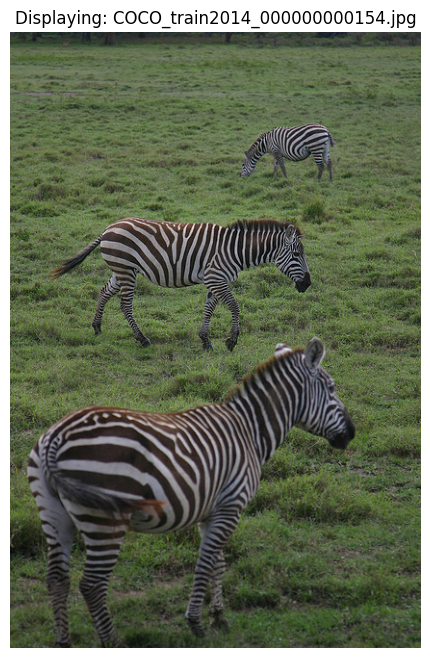

In [36]:
import tarfile
from PIL import Image
import io
import matplotlib.pyplot as plt
import os

# 1. Define the path to your downloaded .tar.gz file
#    (Using the exact path you provided)

with tarfile.open(tar_gz_path, "r:gz") as tar:
    print(f"Successfully opened {tar_gz_path}")

    # 3. List some image files within the archive (optional, for inspection)
    image_files_in_archive = []
    for member in tar.getmembers():
        if member.isfile() and member.name.lower().endswith(('.png', '.jpg', '.jpeg', '.gif', '.bmp', '.webp')):
            image_files_in_archive.append(member.name)
    
    else:
        print(f"\nFound {len(image_files_in_archive)} image files. First few:")
        for i, img_name in enumerate(image_files_in_archive[:5]): # Print first 5
            print(f"- {img_name}")

        # 4. Select an image file to extract and display
        #    Let's pick the first one found for this example.
        #    You can change this to any valid image name from the list.
        image_to_display_name = image_files_in_archive[0]
        print(f"\nAttempting to display: {image_to_display_name}")

        # 5. Extract the selected image file into memory
        image_member_info = tar.getmember(image_to_display_name)
        image_file_object = tar.extractfile(image_member_info)
        
        if image_file_object:
            image_data = image_file_object.read()
            image_file_object.close()

            # 6. Open the image data using Pillow (PIL) from memory
            try:
                image = Image.open(io.BytesIO(image_data))
                
                # Ensure image is in RGB format for consistent display
                if image.mode != "RGB":
                    image = image.convert("RGB")

                # 7. Display the image using matplotlib
                plt.figure(figsize=(8, 8)) # Optional: Adjust figure size
                plt.imshow(image)
                plt.title(f"Displaying: {image_to_display_name}")
                plt.axis('off')  # Hide axes
                plt.show()
                
            except Exception as e_pil:
                print(f"Error opening image {image_to_display_name} with Pillow: {e_pil}")
        else:
            print(f"Could not extract {image_to_display_name} from the archive.")